# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH)  # TODO: read PATIENTS_PATH with pd.read_csv

# TODO: print the shape and the dtypes of patients
print(patients.shape)
display(patients.dtypes)

exploratory_chart = (
    alt.Chart(patients)
    .mark_point(filled=True, size=90)
    .encode(
        x=alt.X(
            "sessions_attended:Q",
            title="Sessions attended (of 36)"
        ),
        y=alt.Y(
            "walk_distance_m:Q",
            title="Six-minute walk distance (m)",
            scale=alt.Scale(zero=False)
        ),
        color=alt.Color("program:N", title="Program"),
        shape=alt.Shape("program:N", title="Program"),
        tooltip=[
            "patient_id:N",
            "program:N",
            "sessions_attended:Q",
            "walk_distance_m:Q"
        ]
    )
    .properties(
        title="Sessions attended and six-minute walk distance"
    )
)  # TODO: the Altair scatter plot README Task 1.1 describes

# TODO: save exploratory_chart to EXPLORATORY_SPEC_PATH with .save()
exploratory_chart.save(EXPLORATORY_SPEC_PATH)

exploratory_chart

(12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

TODO: Replace this line with a few sentences: the question the chart explores, what one point represents, one pattern you see, and why twelve patients cannot show that attending more sessions causes a longer walk.

This chart explores whether patients who attended more rehabilitation were more likely to walk further during the six-minute walk test at discharge, and whether this pattern differs between the two programs. Each point on the graph represents one patient. Overall, the graph has an upward tend showing that patients who attended more sessions generally have longer walk distances. However, the fact that there are only twelve patients that additionally weren't randomly assigned to attendance levels or programs is too small a sample size to show that attending more sessions causes a longer walk. 

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


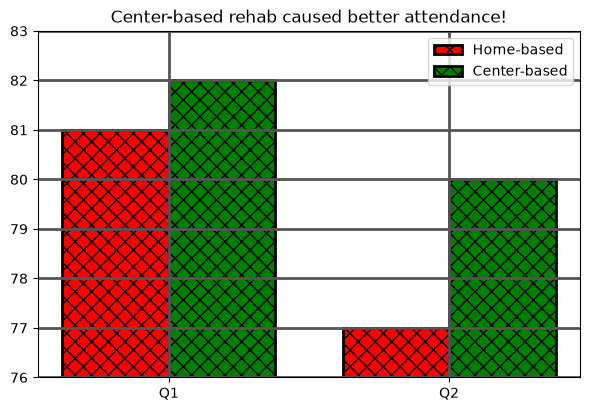

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {
        "category": "unsupported claim",
        "problem": "The chart makes a claim the data cannot prove.",
        "repair": "Only describe what the data shows."
    },
    {
        "category": "truncated baseline",
        "problem": "The y-axis does not start at zero.",
        "repair": "Start the y-axis at zero."
    },
    {
        "category": "missing unit",
        "problem": "The y-axis does not show the percent unit.",
        "repair": "Add percent (%) to the y-axis label."
    },
    {
        "category": "color-only encoding",
        "problem": "The programs are only separated by color.",
        "repair": "Use color and another visual difference."
    },
    {
        "category": "distracting decoration",
        "problem": "Extra decoration distracts from the data.",
        "repair": "Remove unnecessary decoration."
    },
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The chart makes a claim the data cannot prove.
    repair: Only describe what the data shows.
truncated baseline: The y-axis does not start at zero.
    repair: Start the y-axis at zero.
missing unit: The y-axis does not show the percent unit.
    repair: Add percent (%) to the y-axis label.
color-only encoding: The programs are only separated by color.
    repair: Use color and another visual difference.
distracting decoration: Extra decoration distracts from the data.
    repair: Remove unnecessary decoration.


### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

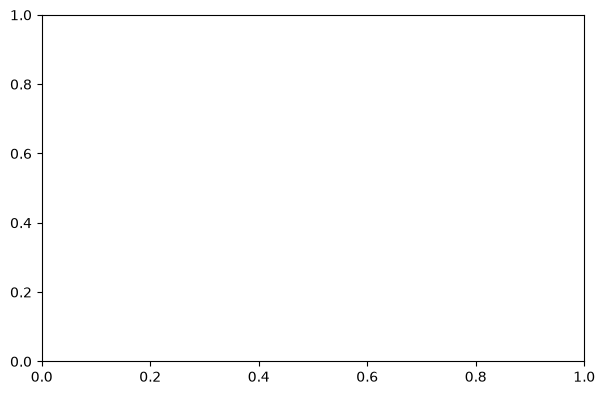

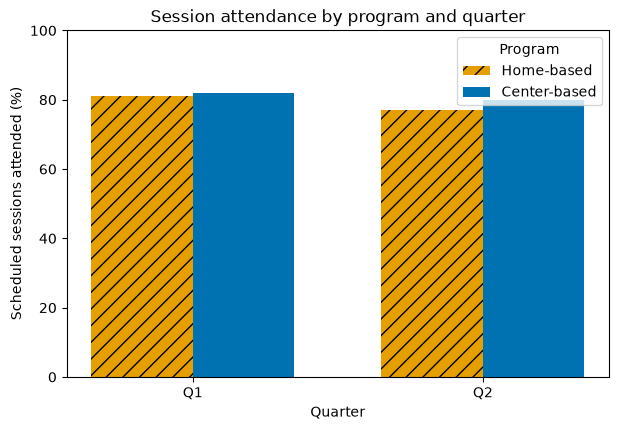

y-axis runs from 0.0 to 100.0


In [5]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

x = np.arange(2)
width = 0.35

redesign_ax.bar(
    x - width / 2,
    home,
    width,
    label="Home-based",
    color=ORANGE,
    hatch="//"
)

redesign_ax.bar(
    x + width / 2,
    center,
    width,
    label="Center-based",
    color=BLUE
)

redesign_ax.set_xticks(x)
redesign_ax.set_xticklabels(["Q1", "Q2"])

redesign_ax.set_ylim(0, 100)
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_title("Session attendance by program and quarter")
redesign_ax.legend(title="Program")

redesign_fig.savefig(
    REDESIGN_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
followup = pd.read_csv(FOLLOWUP_PATH)
display(followup) # TODO: read FOLLOWUP_PATH with pd.read_csv
# TODO: display followup

question = "How does our goal success change across follow-up visits for each program?"  # TODO: the comparison the chart should help the coordinator make
audience = "The program coordinator, who will use the chart to compare the two programs at hand" # TODO: who reads the chart and what they will use it for
intended_claim = "Goal achievement increased across follow-up visits in both programs."  # TODO: the one descriptive conclusion the chart supports
y_measure = "Percent of patients who met the 150-minute weekly exercise goal."  # TODO: what the y-axis measures, with its unit
grain = "One row represents one program at one follow-up visit."  # TODO: what one row of the plotting table and one point on a line represent
data_types = {
    "program": "categorical",
    "visit_number": "ordinal",
    "goal_met_pct": "quantitative",
}

supporting_data = followup[
    ["program", "visit_number", "goal_met_pct"]
]  # TODO: the three plotted columns of followup

# TODO: save supporting_data to SUPPORTING_DATA_PATH without the row index
supporting_data.to_csv(
    SUPPORTING_DATA_PATH,
    index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

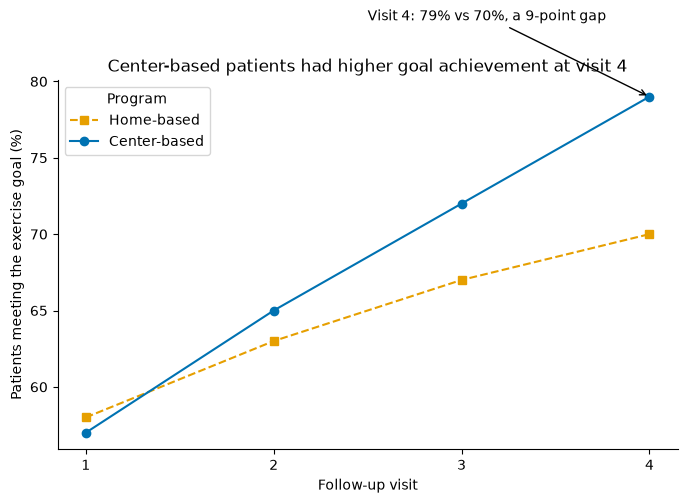

In [7]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

# TODO: draw one line per program on explanatory_ax, with visit_number on x and goal_met_pct on y,
# and finish the chart as README Task 3.2 describes

#home based
explanatory_ax.plot(
    home_goals["visit_number"],
    home_goals["goal_met_pct"],
    color=ORANGE,
    marker="s",
    linestyle="--",
    label="Home-based"
)

# Center-based
explanatory_ax.plot(
    center_goals["visit_number"],
    center_goals["goal_met_pct"],
    color=BLUE,
    marker="o",
    linestyle="-",
    label="Center-based")

explanatory_ax.annotate(
    "Visit 4: 79% vs 70%, a 9-point gap",
    xy=(4, 79),
    xytext=(2.5, 84),
    arrowprops={"arrowstyle": "->"}
)

# Labels and title
explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting the exercise goal (%)")
explanatory_ax.set_title(
    "Center-based patients had higher goal achievement at visit 4"
)

explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.legend(title="Program")

# Remove unnecessary borders
explanatory_ax.spines["top"].set_visible(False)
explanatory_ax.spines["right"].set_visible(False)



# TODO: save explanatory_fig to EXPLANATORY_PATH with dpi=150 and bbox_inches="tight"
explanatory_fig.savefig(
    EXPLANATORY_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [8]:
text_alternative = (
    "Line chart showing the percent of patients meeting the exercise goal across the four follow-up visits. "
    "Goal achievement did in fact increase in both programs. "
    "At visit 4, Center-based was 79 and Home-based was 70%, a 9-point difference."
    "These results are not conclusive of the results or show that either program caused the difference."
) # TODO: one paragraph, as README Task 3.3 describes

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative,
}

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)

with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)

### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

1. In grayscale, the bar chart uses hatching (adding a pattern), and the line chart uses different markers and line styles to separate the programs.

2. The annotation points to Center-based at visit 4 (79%). It stays descriptive by comparing 79% with 70%, a 9-point gap, but not exactly claiming that there is causation

3. No

4. The sample size is simply too small

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [9]:
from check_assignment import run_checks

_ = run_checks()

Checks: used the bundled copy because the latest could not be fetched (URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1032)>).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]